In [1]:
import pandas as pd
import os
#from fastai.vision.all import *
from fastai.tabular.all import *

C:\Users\bowan\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
Image_path = '../images_assorted'

if os.path.exists(Image_path):
    print("The file exists.")
else:
    %run ../GenerateVolumes.ipynb

The file exists.


In [3]:
df_path = '../image_data_assorted.csv'
df = pd.read_csv(df_path)

In [4]:
df.head()

,Radius,X_Position,Y_Position,Area,Surface2d,Volume,image_path,mask_path,shape
0,83,339,254,3444,283,571787,images_assorted/image_1.png,masks_assorted/mask_1.png,triange
1,67,203,421,2244,229,300763,images_assorted/image_2.png,masks_assorted/mask_2.png,triange
2,61,231,360,3721,244,226981,images_assorted/image_3.png,masks_assorted/mask_3.png,square
3,51,227,376,8167,160,555366,images_assorted/image_4.png,masks_assorted/mask_4.png,circle
4,57,347,420,3249,228,185193,images_assorted/image_5.png,masks_assorted/mask_5.png,square


In [5]:
columns = df.columns


cont_names = [col for col in columns if col != 'shape'] # removes shapes column data
cont_names = [col for col in cont_names if col != 'image_path'] # removes image_path column data
cont_names = [col for col in cont_names if col != 'mask_path'] # removes mask_path column data


In [6]:
cont_names = ['X_Position', 'Y_Position', 'Area', 'Surface2d', 'Volume','Radius']

cat_names = [] # insert column names to use as inputs with Numerical values here
target = 'shape'

In [7]:
# use this to check if columns are in the right list
print(cat_names)
print(cont_names)


[]
['X_Position', 'Y_Position', 'Area', 'Surface2d', 'Volume', 'Radius']


In [8]:
batch_size = 64      # where you declare batch size

dls = TabularDataLoaders.from_csv( 
df_path,                     # Path to the CSV file 
y_names=target,              # Name of the target column 
cat_names=cat_names,         # List of categorical data column names 
cont_names=cont_names,       # List of continuous values column names 
bs=batch_size,               # Batch size
procs=[Categorify, FillMissing, Normalize], # The 
batch_tfms=[IntToFloatTensor()]             # Makes sure numerical values are in right data type
)

In [9]:
len(cont_names)

6

In [10]:
dls.show_batch()

,X_Position,Y_Position,Area,Surface2d,Volume,Radius,shape
0,146.999998,267.999999,759.999822,133.000003,5.931902e+04,38.999999,triange
1,133.000004,217.999999,3280.000090,276.999999,5.314410e+05,81.000000,triange
2,412.999997,335.000002,961.000076,123.999996,2.979100e+04,31.000000,square
3,327.999998,388.000003,5183.999901,287.999999,3.732480e+05,72.000000,square
4,393.999998,223.000001,4299.000127,115.999998,2.120670e+05,37.000000,circle
5,262.000000,162.000003,20601.999677,254.000000,2.224966e+06,81.000000,circle
6,180.999998,308.999998,1962.000014,78.000003,6.541703e+04,24.999999,circle
7,143.000000,140.000005,12861.000221,200.999999,1.097510e+06,64.000000,circle
8,192.999999,163.000001,4418.000027,320.999999,8.305840e+05,94.000000,triange
9,78.000006,269.999999,35950.000285,335.999998,5.128847e+06,106.999999,circle


In [11]:



learn = tabular_learner(dls, metrics=accuracy)


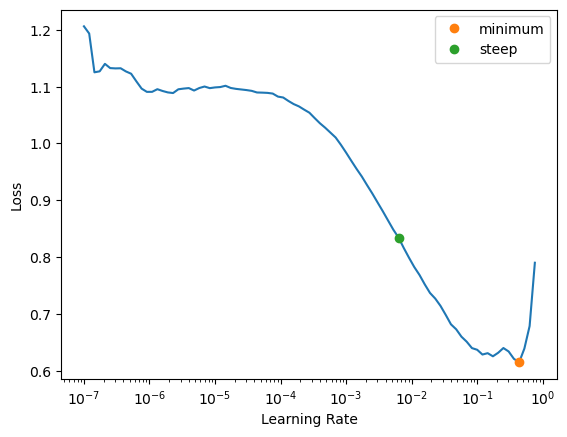

In [12]:
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

In [13]:

learn.fit_one_cycle(200,lr_max=lr_steep)

epoch,train_loss,valid_loss,accuracy,time
0,0.882825,0.983518,0.635000,00:00
1,0.736204,0.783932,0.740000,00:00
2,0.627260,0.569716,0.885000,00:00
3,0.533853,0.403205,0.945000,00:00
4,0.454170,0.293209,0.945000,00:00
5,0.391620,0.220357,0.965000,00:00
6,0.332461,0.168756,0.980000,00:00
7,0.284232,0.136961,0.970000,00:00
8,0.241838,0.130886,0.945000,00:00
9,0.206351,0.085044,0.985000,00:00


<bound method Recorder.plot_loss of Recorder>


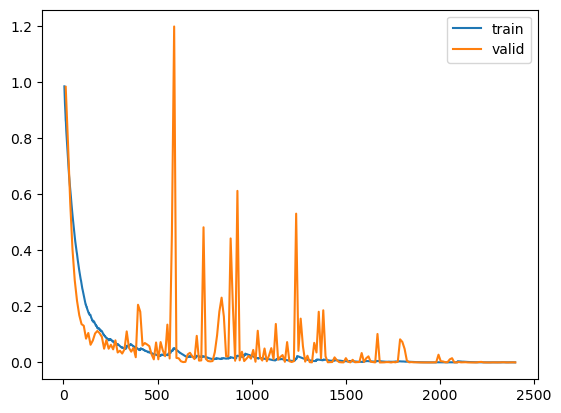

In [14]:
# Plot the losses
learn.recorder.plot_loss()
print(learn.recorder.plot_loss)
# Set the y-axis limits (replace with your desired limits)
#plt.ylim(0, 5)  # sets y-axis limits 
# Show the plot with updated y-limits
plt.show()

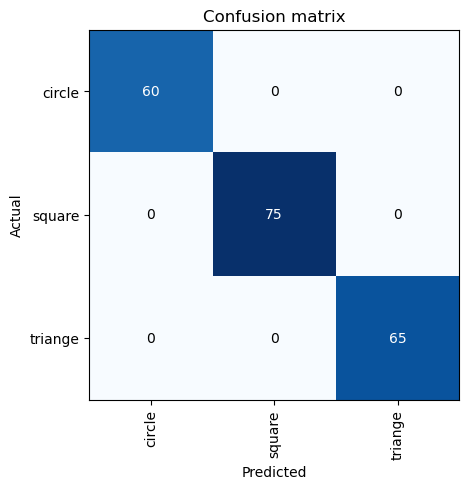

In [15]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

In [16]:


learn.export('exported_classification_tabular_model.pkl')
 


In [17]:
# import

learn2 = load_learner('exported_classification_tabular_model.pkl')   # using learner2 to show its loading

In [19]:

# Get the nth row (e.g., 2nd row)
n = 1  # Remember, indexing starts at 0
orginalrow = df.iloc[n]
print(f'GroundTurth value {orginalrow["Radius"]}')
                 
df_selected = df[cont_names]
nth_row = df_selected.iloc[n]

DataSeries_with_appended_prediction, ClassID, Confidence =learn2.predict(nth_row)

print(DataSeries_with_appended_prediction)
print(ClassID)
print(Confidence)


GroundTurth value 67


   X_Position  Y_Position     Area  Surface2d    Volume    Radius  shape
0   -0.474966    1.525299 -0.61468  -0.016259 -0.464785  0.058865    2.0
tensor(2)
tensor([9.4531e-06, 1.6861e-05, 9.9997e-01])


In [ ]:
print(image_paths[n])

In [ ]:
print(Prediction)
print(ClassID)
print(Confidence)